<a href="https://colab.research.google.com/github/Bndreea/Team-9/blob/main/Group9_updated15/11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#*GROUP 9 PROJECT - Breast Cancer Project*

# **ANDREEA - Diagnostic Data Set (WDBC)**


[Dataset](/https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic)

Summary:\
1.Data clean-up and visualisation\
2.Model selection\
3.Model training

# 1.Loading data

Loading the Wisconsin Breast Cancer Dataset from UCI Irvine.

In [ ]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# Fetch the Breast Cancer Wisconsin (Diagnostic) dataset
wdbc = fetch_ucirepo(id=17)

# Extract features and targets
x = wdbc.data.features
y = wdbc.data.targets

# Display information and preview
print("Diagnostic Features Shape:", x.shape)
display(x.head())
print("Diagnostic Targets Shape:", y.shape)
display(y.head())
print()
print("Information about features")
display(x.info())
display(x.describe())
print("Inforation about target")
display(y.info())
display(y.describe())

Diagnostic Features Shape: (569, 30)


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Diagnostic Targets Shape: (569, 1)


,Diagnosis
0,M
1,M
2,M
3,M
4,M



Information about features
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-n

None

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Inforation about target
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Diagnosis  569 non-null    object
dtypes: object(1)
memory usage: 4.6+ KB


None

,Diagnosis
count,569
unique,2
top,B
freq,357


There are no missing values.

#2.Outliers

Plotting a box plot for the normalized 30 features to identify outliers.

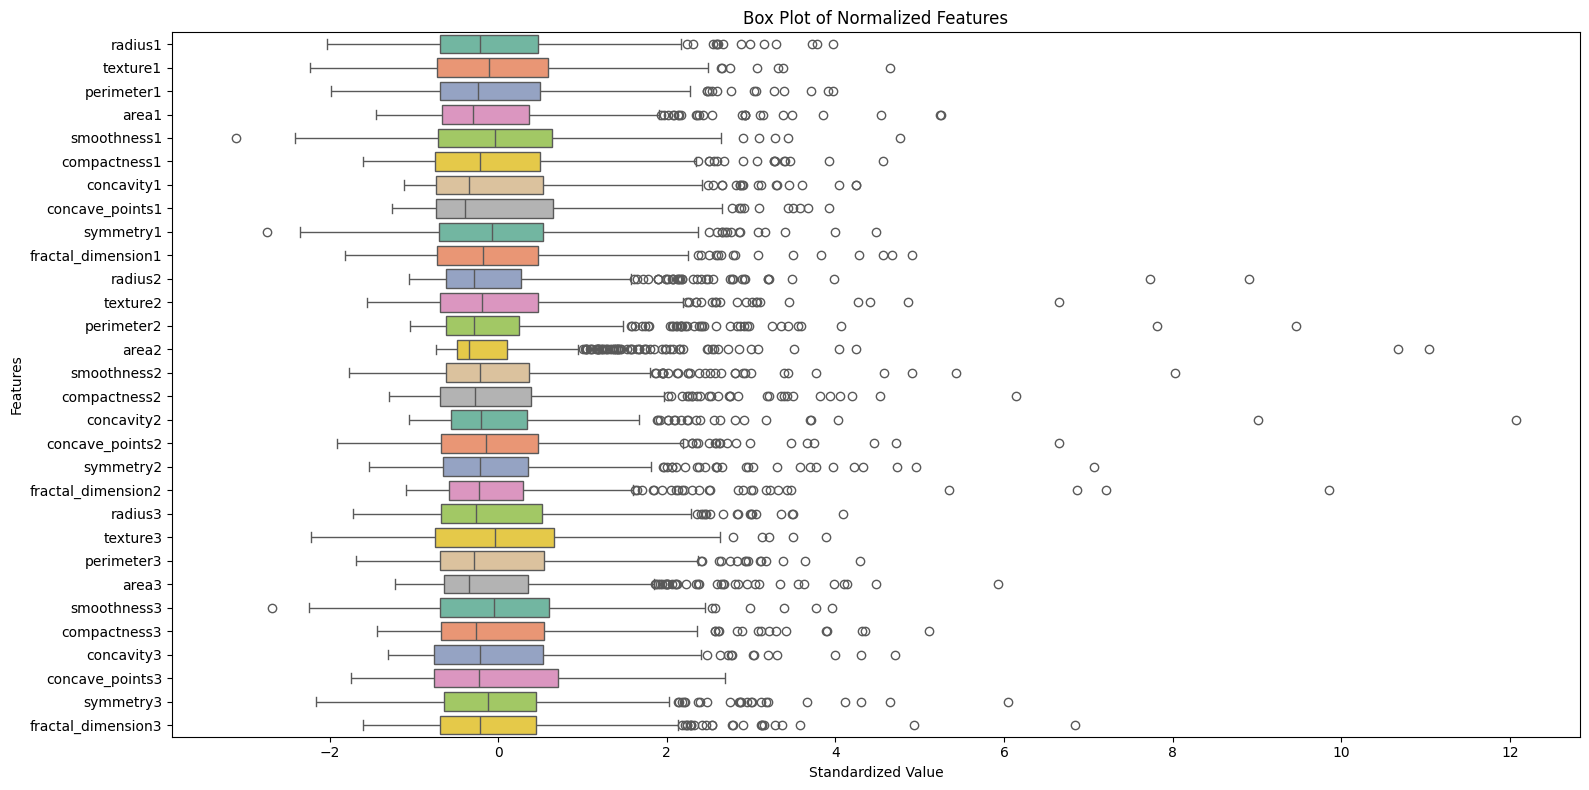

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Instantiate the scaler
scaler = StandardScaler()

# Select numeric columns (excluding any non-numeric fields if present)
numeric_cols = x.select_dtypes(include='number').columns

# Fit and transform the features
x_scaled_array = scaler.fit_transform(x[numeric_cols])
x_scaled = pd.DataFrame(x_scaled_array, columns=numeric_cols)

# Plot the box plot for the 30 scaled features
plt.figure(figsize=(16, 8))
sns.boxplot(data=x_scaled, orient='h', palette='Set2')
plt.title('Box Plot of Normalized Features')
plt.xlabel('Standardized Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

What does one do with 1 billion outliers?

Plotting a bar graph representing the distribution of malignant and bening cases.

Diagnosis Value Counts:
Diagnosis
B    357
M    212
Name: count, dtype: int64
Ratios:
Malignant: 0.373
Benign: 0.627


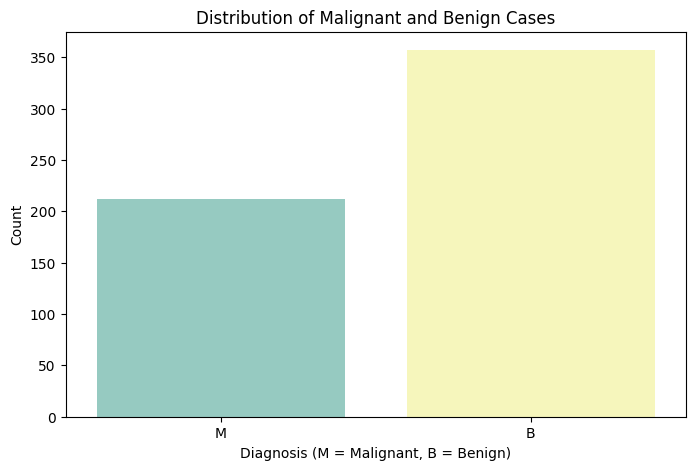

In [ ]:
import matplotlib.pyplot as plt

# Calculate class distribution
diagnosis_counts = y['Diagnosis'].value_counts()
print("Diagnosis Value Counts:")
print(diagnosis_counts)

print("Ratios:")
print(f"Malignant: {diagnosis_counts['M'] / (diagnosis_counts['B'] + diagnosis_counts['M']):.3g}")
print(f"Benign: {diagnosis_counts['B']/(diagnosis_counts["B"]+diagnosis_counts['M']):.3g}")

# Plotting
plt.figure(figsize=(8, 5))
sns.countplot(data=y, x='Diagnosis', palette='Set3', hue='Diagnosis', legend=False)
plt.title('Distribution of Malignant and Benign Cases')
plt.xlabel('Diagnosis (M = Malignant, B = Benign)')
plt.ylabel('Count')
plt.grid(False)
plt.show()

#3.Model Training

## 3.1 Logistic Regression Model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

# Split the dataset into train and validation sets
# Map B to 0 and M to 1
x_train, x_val, y_train, y_val = train_test_split(
    x_scaled,
    y['Diagnosis'].map({'B': 0, 'M': 1}),
    test_size=0.2,
    random_state=42,
    stratify=y['Diagnosis']
)

# Instantiate and fit the Logistic Regression model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(x_train, y_train)

# Predictions
y_pred = log_reg.predict(x_val)
y_pred_proba = log_reg.predict_proba(x_val)[:, 1]

# Convert y_val from strings ('B', 'M') to numeric (0, 1) if they are not already
y_val_numeric = y_val.map({'B': 0, 'M': 1}) if y_val.dtype == 'object' else y_val

# Calculate basic metrics
accuracy = accuracy_score(y_val_numeric, y_pred)
precision = precision_score(y_val_numeric, y_pred)
recall = recall_score(y_val_numeric, y_pred)
f1_weighted = f1_score(y_val_numeric, y_pred, average='weighted')

# Calculate specificity
tn, fp, fn, tp = confusion_matrix(y_val_numeric, y_pred).ravel()
specificity = tn / (tn + fp)

# Calculate Area Under Curves
roc_auc = roc_auc_score(y_val_numeric, y_pred_proba)
precisions, recalls, thresholds = precision_recall_curve(y_val_numeric, y_pred_proba)
pr_auc = auc(recalls, precisions)

# Print metrics
print(f"=== Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy:.4f}")
print(f"Precision:        {precision:.4f}")
print(f"Recall:           {recall:.4f}")
print(f"Specificity:      {specificity:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted:.4f}")
print(f"ROC-AUC:          {roc_auc:.4f}")
print(f"PR-AUC:           {pr_auc:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val_numeric, y_pred))


NameError: name 'accuracy_score' is not defined

## 3.2 Random Forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

# Instantiate and fit the Random Forest model
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(x_train, y_train)

# Predictions
y_pred_rf = rf_clf.predict(x_val)
y_pred_proba_rf = rf_clf.predict_proba(x_val)[:, 1]

# Calculate metrics
accuracy_rf = accuracy_score(y_val, y_pred_rf)
precision_rf = precision_score(y_val, y_pred_rf)
recall_rf = recall_score(y_val, y_pred_rf)
f1_weighted_rf = f1_score(y_val, y_pred_rf, average='weighted')

# Calculate specificity
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_val, y_pred_rf).ravel()
specificity_rf = tn_rf / (tn_rf + fp_rf)

# Calculate Area Under Curves
roc_auc_rf = roc_auc_score(y_val, y_pred_proba_rf)
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_val, y_pred_proba_rf)
pr_auc_rf = auc(recalls_rf, precisions_rf)

# Print metrics
print(f"=== Random Forest Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy_rf:.4f}")
print(f"Precision:        {precision_rf:.4f}")
print(f"Recall:           {recall_rf:.4f}")
print(f"Specificity:      {specificity_rf:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted_rf:.4f}")
print(f"ROC-AUC:          {roc_auc_rf:.4f}")
print(f"PR-AUC:           {pr_auc_rf:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val, y_pred_rf))

## 3.3 Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

# Instantiate and fit the SVM model
svm_clf= SVC(kernel='linear', random_state=42)

# Prediction
svm_clf.fit(x_train,y_train)
y_pred_svm=svm_clf.predict(x_val)
y_scores_svm = svm_clf.decision_function(x_val)

# Calculate basic metrics
accuracy_svm = accuracy_score(y_val, y_pred_svm)
precision_svm = precision_score(y_val, y_pred_svm)
recall_svm = recall_score(y_val, y_pred_svm)
f1_weighted_svm = f1_score(y_val, y_pred_svm, average='weighted')

# Calculate specificity
tn_svm, fp_svm, fn_svm, tp_svm = confusion_matrix(y_val, y_pred_svm).ravel()
safety_denom_spec = (tn_svm + fp_svm)
specificity_svm = tn_svm / safety_denom_spec if safety_denom_spec > 0 else 0.0

# Calculate Area Under Curves (ROC-AUC and PR-AUC) using decision scores
roc_auc_svm = roc_auc_score(y_val, y_scores_svm)
precisions_svm, recalls_svm, thresholds_svm = precision_recall_curve(y_val, y_scores_svm)
pr_auc_svm = auc(recalls_svm, precisions_svm)

# Print metrics
print(f"=== SVM Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy_svm:.4f}")
print(f"Precision:        {precision_svm:.4f}")
print(f"Recall:           {recall_svm:.4f}")
print(f"Specificity:      {specificity_svm:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted_svm:.4f}")
print(f"ROC-AUC:          {roc_auc_svm:.4f}")
print(f"PR-AUC:           {pr_auc_svm:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val, y_pred_svm))


# **SEB - Prognostic Data Set (WPBC)**

*[dataset link](https://archive.ics.uci.edu/dataset/16/breast+cancer+wisconsin+prognostic)*

> The three measurements recorded in the dataset are:
>
> 1 - Mean Average
>
> 2 - Standard Error (SE)
>
> 3 - Worst (Mean of the 3 largest values)

(for example: radius2 = SE radius, area3 = Worst area)

##1: Data Loading
Use Python libraries to load and visualise the dataset:

**Pandas** - Data manipulation

**NumPy** - Numerical operations

**Matplotlib/Seaborn** - Visualisation using graphs

**ucimlrepo** - Specific library for accessing our required dataset

In [40]:
!pip install ucimlrepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

The Wisconsin Prognostic Breast Cancer dataset was obtained from the UCI Machine Learning Repository. The dataset contains nuclear measurements from breast cancer patients with corresponding information on whether it was recurring.

In [41]:
wpbc = fetch_ucirepo(id=16)
X = wpbc.data.features
#X represents the independent variables (the predictor variables/measurements)
Y = wpbc.data.targets
#Y represents the dependent varaibles (the target variable/outcome)

In [42]:
print("Sizes of X (main table), Y (target table)")
print("X:", X.shape)
print("Y:", Y.shape)
print()
print("Column names, data types and missing values:")
print("X:")
X.info()
print()
print("Y:")
Y.info()
print()
print("X table")
display(X)
print("X statistics summary")
display(X.describe())

Sizes of X (main table), Y (target table)
X: (198, 33)
Y: (198, 1)

Column names, data types and missing values:
X:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Time                198 non-null    int64  
 1   radius1             198 non-null    float64
 2   texture1            198 non-null    float64
 3   perimeter1          198 non-null    float64
 4   area1               198 non-null    float64
 5   smoothness1         198 non-null    float64
 6   compactness1        198 non-null    float64
 7   concavity1          198 non-null    float64
 8   concave_points1     198 non-null    float64
 9   symmetry1           198 non-null    float64
 10  fractal_dimension1  198 non-null    float64
 11  radius2             198 non-null    float64
 12  texture2            198 non-null    float64
 13  perimeter2          198 non-null    flo

,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status
0,31,18.02,27.60,117.50,1013.0,0.09489,0.10360,0.10860,0.07055,0.1865,...,139.70,1436.0,0.11950,0.1926,0.3140,0.11700,0.2677,0.08113,5.0,5.0
1,61,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,184.60,2019.0,0.16220,0.6656,0.7119,0.26540,0.4601,0.11890,3.0,2.0
2,116,21.37,17.44,137.50,1373.0,0.08836,0.11890,0.12550,0.08180,0.2333,...,159.10,1949.0,0.11880,0.3449,0.3414,0.20320,0.4334,0.09067,2.5,0.0
3,123,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,98.87,567.7,0.20980,0.8663,0.6869,0.25750,0.6638,0.17300,2.0,0.0
4,27,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,152.20,1575.0,0.13740,0.2050,0.4000,0.16250,0.2364,0.07678,3.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,10,22.52,21.92,146.90,1597.0,0.07592,0.09162,0.06862,0.06367,0.1728,...,162.10,1902.0,0.08191,0.1319,0.1056,0.09378,0.2061,0.05788,6.0,2.0
194,8,15.44,31.18,101.00,740.4,0.09399,0.10620,0.13750,0.06500,0.1735,...,112.60,929.0,0.12720,0.2362,0.2975,0.12860,0.2914,0.08024,1.5,0.0
195,12,17.17,29.19,110.00,915.3,0.08952,0.06655,0.06583,0.05068,0.1793,...,132.50,1295.0,0.12610,0.1572,0.2141,0.09520,0.3362,0.06033,3.7,0.0
196,3,21.42,22.84,145.00,1440.0,0.10700,0.19390,0.23800,0.13180,0.1884,...,198.30,2375.0,0.14980,0.4379,0.5411,0.22150,0.2832,0.08981,3.0,NaN


X statistics summary


,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status
count,198.000000,198.000000,198.00000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,...,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,194.000000
mean,46.732323,17.412323,22.27601,114.856566,970.040909,0.102681,0.142648,0.156243,0.086776,0.192754,...,140.347778,1404.958586,0.143921,0.365102,0.436685,0.178778,0.323404,0.090828,2.847475,3.211340
std,34.462870,3.161676,4.29829,21.383402,352.149215,0.012522,0.049898,0.070572,0.033877,0.027437,...,28.892279,586.006972,0.022004,0.163965,0.173625,0.045181,0.075161,0.021172,1.937964,5.479276
min,1.000000,10.950000,10.38000,71.900000,361.600000,0.074970,0.046050,0.023980,0.020310,0.130800,...,85.100000,508.100000,0.081910,0.051310,0.023980,0.028990,0.156500,0.055040,0.400000,0.000000
25%,14.000000,15.052500,19.41250,98.160000,702.525000,0.093900,0.110200,0.106850,0.063670,0.174075,...,118.075000,947.275000,0.129325,0.248700,0.322150,0.152650,0.275950,0.076577,1.500000,0.000000
50%,39.500000,17.290000,21.75000,113.700000,929.100000,0.101900,0.131750,0.151350,0.086075,0.189350,...,136.500000,1295.000000,0.141850,0.351300,0.402350,0.179250,0.310300,0.086890,2.500000,1.000000
75%,72.750000,19.580000,24.65500,129.650000,1193.500000,0.110975,0.172200,0.200500,0.103925,0.209325,...,159.875000,1694.250000,0.154875,0.423675,0.541050,0.207125,0.358800,0.101375,3.500000,4.000000
max,125.000000,27.220000,39.28000,182.100000,2250.000000,0.144700,0.311400,0.426800,0.201200,0.304000,...,232.200000,3903.000000,0.222600,1.058000,1.170000,0.290300,0.663800,0.207500,10.000000,27.000000


##2: Data Cleanup
[1] Remove unnecessary columns:

- "ID" (doesn't contain important data)
  
- "Outcome" (this hides the value that the models will try to predict)
  
- "Time" (could mislead the models with data representing two slightly different things)

[2] Check for duplicate rows

[3] Fill in the missing values to not throw away data points

In [43]:
print(X.columns.tolist())

['Time', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'tumor_size', 'lymph_node_status']


Apparently the "ID" and "Outcome" columns don't appear which is good, so I just have to remove the "Time" column.

Also checking for any duplicate rows in the main dataset, and missing values in the outcomes.

In [44]:
X = X.drop(columns=["Time"])
print(X.shape)
print(X.isna().sum())
print()
print("Duplicate rows:", X.duplicated().sum())
print("Missing outcomes:", Y.isna().sum().sum())

(198, 32)
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
tumor_size            0
lymph_node_status     4
dtype: int64

Duplicate rows: 0
Missing outcomes: 0


So there are only 4 N/A values, all in the "lymph_node_status" column.

There are also no duplicate rows, so we don't have to remove any rows.

I'll fill in the missing values during the preprocessing using imputation as to not skew the data.

##3: Count Outcomes
Check the outomes and visualise them in a graph to check whether the data is balanced.

Outcome
N          151
R           47
Name: count, dtype: int64



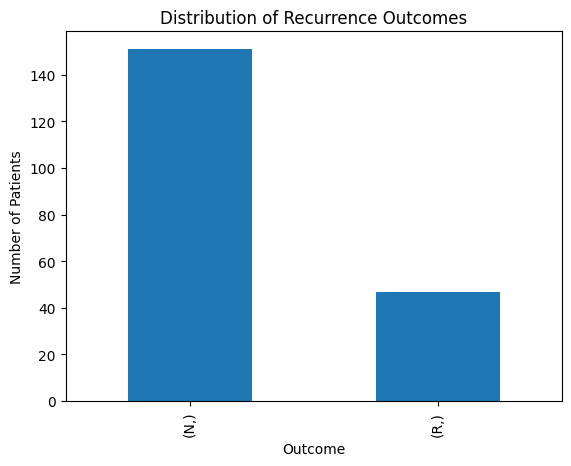

In [45]:
print(Y.value_counts())
print()
Y.value_counts().plot(kind="bar")
plt.title("Distribution of Recurrence Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.show()

This graph shows a clear imbalance: roughly 3 out of every 4 patients did not experience recurrence.

> This means we have to focus especially on: Recall, precision, F1-score and PR-AUC.

##4: EDA (Comparison of Measurements)
Below, I'll plot a few box plots measuring key characteristics with whether recurrence happened or not.
>I'll choose Mean Radius, Mean Concavity, and SE of Symmetry

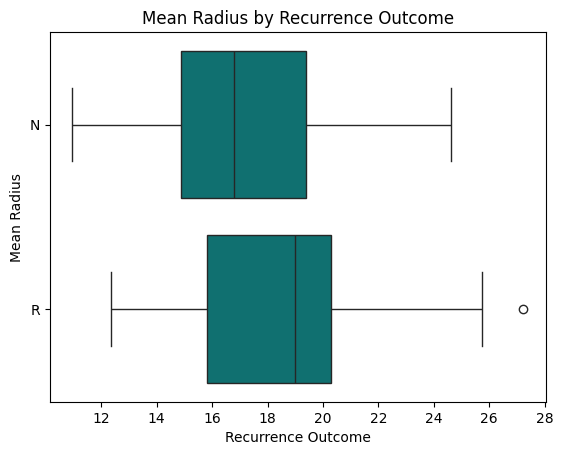

In [46]:
sns.boxplot(x=X["radius1"],y=Y.iloc[:,0],color="teal")
plt.title("Mean Radius by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("Mean Radius")
plt.show()

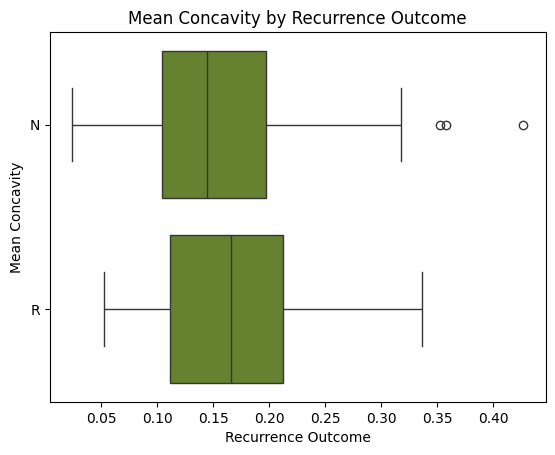

In [47]:
sns.boxplot(x=X["concavity1"],y=Y.iloc[:,0],color="olivedrab")
plt.title("Mean Concavity by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("Mean Concavity")
plt.show()

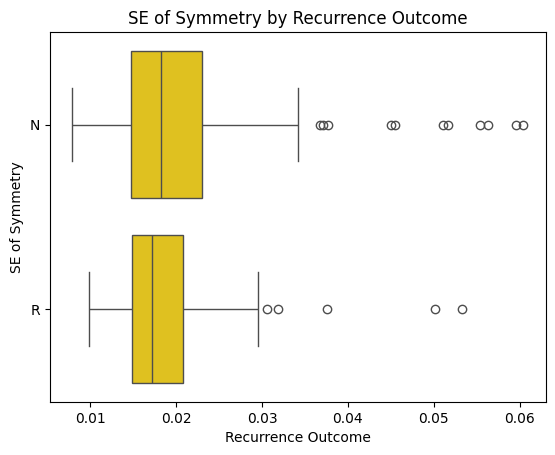

In [48]:
sns.boxplot(x=X["symmetry2"],y=Y.iloc[:,0],color="gold")
plt.title("SE of Symmetry by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("SE of Symmetry")
plt.show()

##5: Preprocessing
Make some changes to the data so the data models are able to read it properly:
> - Seperate target variable (Convert N -> 0 (no recurrence) and R -> 1 (recurrence))
>
>- Use scikit-learn to import the model tools
>
>- Remove columns to match with the WDBC dataset
>
>- Seperate the cohort into stratified groups

In [49]:
#converts the outcomes from N -> 0, R -> 1
Y = Y.iloc[:,0].map({"N":0,"R":1})
print(Y.value_counts())

Outcome
0    151
1     47
Name: count, dtype: int64


In [50]:
#the preprocesses
from sklearn.impute import SimpleImputer #to fill in missing data
from sklearn.preprocessing import StandardScaler #standardises numerical features
from sklearn.pipeline import Pipeline #runs preprocessing steps and the model in sequence

#the models
from sklearn.linear_model import LogisticRegression #predicts probability of a binary outcome
from sklearn.ensemble import RandomForestClassifier #combines many decision trees to make predictions
from sklearn.svm import SVC #Support Vector Classifier

#evaluation
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict #trains and evaluates a model across multiple folds
from sklearn.metrics import confusion_matrix #used to calculate specificity
from sklearn.metrics import ConfusionMatrixDisplay #to visualise the confusion matrices

In [51]:
#creates a process to fill in the missing gaps with the median (less affected by large values)
preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

The WPBC dataset has 2 extra columns: "tumor_size" and "lymph_node_status", so to match the WDBC dataset with the models, I need to remove those columns.

In [52]:
X_nuclear = X.drop(columns=["tumor_size","lymph_node_status"])
print(X_nuclear.shape) #should be (198, 30) now

(198, 30)


Since the data is not very balanced, using stratified cross-validation will make the models more efficient and accurate.

>Since there are 198 patients, using a 5-fold validation gives about 40 patients per group, and around 10 of them having recurrence.
>
>The models will train on 4 groups, then test on the remaining group

In [53]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

##6: The Models
> 1: Logistic Regression
>
> 2: Random Forest
>
> 3: SVM

###6.1: Logistic Regression

In [54]:
#logistic regression pipeline
log_reg = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression(max_iter=1000))
])

#evaluation model
lg_results = cross_validate(
    log_reg,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("Logistic Regression Model Evaluation Metrics")
print("--------------------------------------------")
metricnames = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]
metrickeys = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_average_precision"]
for name, metric in zip(metricnames, metrickeys):
  scores = lg_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
lg_Y_pred = cross_val_predict(log_reg, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, lg_Y_pred).ravel()
lg_specificity = tn/(tn+fp)
print("Specificity:",round(lg_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,lg_Y_pred))

Logistic Regression Model Evaluation Metrics
--------------------------------------------
Accuracy: 0.742 ± 0.031
Precision: 0.294 ± 0.246
Recall: 0.169 ± 0.152
F1 Score: 0.213 ± 0.185
ROC-AUC: 0.620 ± 0.117
PR-AUC: 0.389 ± 0.118
Specificity: 0.921
Confusion Matrix:
[[139  12]
 [ 39   8]]


###6.2: Random Forest

In [55]:
#random forest doesn't need the data to be standardised, so the preprocessing just needs to fill in the missing values
rf_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

#Random Forest pipeline
rf = Pipeline([
    ("preprocessing", rf_preprocessing),
    ("model", RandomForestClassifier(random_state=42))
])

#evaluation model
rf_results = cross_validate(
    rf,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("Random Forest Model Evaluation Metrics")
print("--------------------------------------")
for name, metric in zip(metricnames, metrickeys):
  scores = rf_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
rf_Y_pred = cross_val_predict(rf, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, rf_Y_pred).ravel()
rf_specificity = tn/(tn+fp)
print("Specificity:",round(rf_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,rf_Y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Random Forest Model Evaluation Metrics
--------------------------------------
Accuracy: 0.753 ± 0.029
Precision: 0.300 ± 0.400
Recall: 0.062 ± 0.081
F1 Score: 0.097 ± 0.122
ROC-AUC: 0.580 ± 0.055
PR-AUC: 0.349 ± 0.078
Specificity: 0.967
Confusion Matrix:
[[146   5]
 [ 44   3]]


###6.3: SVM (Support Vector Machine)

In [58]:
#svm pipeline (rbf allows it to identify non-linear relationships)
svm = Pipeline([
    ("preprocessing", preprocessing),
    ("model", SVC(kernel="linear", probability=True, random_state=42))
])

#evaluation model
svm_results = cross_validate(
    svm,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("SVM Evaluation Metrics")
print("----------------------")
for name, metric in zip(metricnames, metrickeys):
  scores = svm_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
svm_Y_pred = cross_val_predict(svm, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, svm_Y_pred).ravel()
svm_specificity = tn/(tn+fp)
print("Specificity:",round(svm_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,svm_Y_pred))

SVM Evaluation Metrics
----------------------
Accuracy: 0.742 ± 0.020
Precision: 0.267 ± 0.226
Recall: 0.064 ± 0.053
F1 Score: 0.103 ± 0.084
ROC-AUC: 0.586 ± 0.051
PR-AUC: 0.343 ± 0.056
Specificity: 0.954
Confusion Matrix:
[[144   7]
 [ 44   3]]


##7: Data Modelling
>Now that all 3 models are trained and evaluated on the same cross-validation setup, we can visualise the data in a graph.

The metrics used are:
- Confusion Matrix:
\begin{pmatrix}
TN & FP\\
FN & TP
\end{pmatrix}
where TP = True Positive, FP = False Positive, FN = False Negative, TN = True Negative

- Accuracy: Proportion of predictions that were correct

- Precision: Reliability of positive predictions

- Recall: Ability to identify positive cases

- Specificity: Ability to identify negative cases

- F1 Score: Balance between precision and recall

- ROC-AUC: Overall classification ability

- PR-AUC: Precision-recall performance

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Specificity
Model,,,,,,,
Logistic Regression,0.742 ± 0.031,0.294 ± 0.246,0.169 ± 0.152,0.213 ± 0.185,0.620 ± 0.117,0.389 ± 0.118,0.921
Random Forest,0.753 ± 0.029,0.300 ± 0.400,0.062 ± 0.081,0.097 ± 0.122,0.580 ± 0.055,0.349 ± 0.078,0.967
SVM,0.742 ± 0.020,0.267 ± 0.226,0.064 ± 0.053,0.103 ± 0.084,0.586 ± 0.051,0.343 ± 0.056,0.954


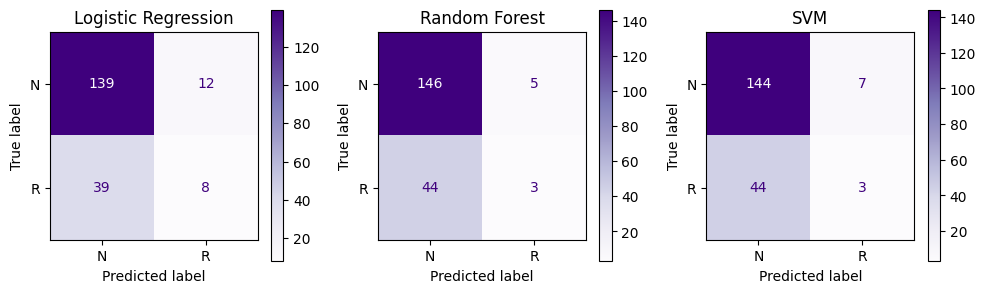

In [83]:
model_results = {
    "Logistic Regression": lg_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

comparison = []

spec_all = [lg_specificity,rf_specificity,svm_specificity]

#display all measurements from all 3 models
for (modelname, modelresult), spec in zip(model_results.items(), spec_all):
  row = {"Model": modelname}
  for name, metric in zip(metricnames, metrickeys):
    scores = modelresult[metric]
    row[name] = f"{scores.mean():.3f} ± {scores.std():.3f}"
  row["Specificity"] = f"{spec:.3f}"
  comparison.append(row)
comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df)

#display confusion matrices from all 3 models
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
predictions = [lg_Y_pred, rf_Y_pred, svm_Y_pred]
model_names = ["Logistic Regression", "Random Forest", "SVM"]

for ax, pred, name in zip(axes, predictions, model_names):
    ConfusionMatrixDisplay.from_predictions(
        Y, pred,
        display_labels=["N", "R"],
        cmap="Purples",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# **OLIVIA – Feature importance and comparison**

# **EHSAN – PCA and further analysis**